# Daily Stock Market Prediction

In [12]:
!rm -rf My-Daily-Python-Learning

In [13]:
!git clone -b trading_stock_market https://github.com/Jalilnkh/My-Daily-Python-Learning

Cloning into 'My-Daily-Python-Learning'...
remote: Enumerating objects: 685, done.
remote: Counting objects: 100% (256/256), done.
remote: Compressing objects: 100% (250/250), done.
remote: Total 685 (delta 117), reused 2 (delta 2), pack-reused 429 (from 2)
Receiving objects: 100% (685/685), 24.73 MiB | 41.32 MiB/s, done.
Resolving deltas: 100% (359/359), done.


In [16]:
%%bash
cd "/content/My-Daily-Python-Learning/Daily Stock Market Prediction"
python3 src/download_nvda_related_100.py \
    --start 2018-01-01 \
    --end 2026-11-06

Fetching 1-10/102: NVDA, AMD, AVGO, MRVL, MU, INTC, TSM, ASML, AMAT, LRCX
Fetching 11-20/102: KLAC, ARM, QCOM, ON, NXPI, MCHP, MPWR, ADI, TXN, ALGM
Fetching 21-30/102: COHU, ACLS, ONTO, TER, LSCC, FORM, RMBS, AMKR, SNPS, CDNS
Fetching 31-40/102: ANET, CSCO, CIEN, LITE, COHR, AAOI, CRDO, ALAB, GLW, APH
Fetching 41-50/102: TEL, KEYS, FN, CALX, BELFB, SMCI, DELL, HPE, IBM, NTAP
Fetching 51-60/102: WDC, STX, SNDK, TSSI, FLEX, JBL, CRWV, NBIS, APLD, IREN
Fetching 61-70/102: CIFR, WULF, HUT, BTDR, EQIX, DLR, IRM, RXT, VRT, ETN
Fetching 71-80/102: NVT, MOD, GEV, CEG, VST, TLN, NRG, GNRC, POWL, EMR
Fetching 81-90/102: HUBB, AES, D, PWR, EME, FIX, MTZ, DY, STRL, IESC
Fetching 91-100/102: APG, PRIM, MYRG, ACM, WCC, MSFT, AMZN, GOOGL, META, ORCL
Fetching 101-102/102: SPY, QQQ
Finished: 100/100 stocks downloaded
OHLCV observations: 207,224; model panel observations: 202,776
Files saved in: /content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output
IMPORTANT: Co-movement during an e

In [21]:
import os
output_dir = "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/output"
if os.path.exists(output_dir):
    print(os.listdir(output_dir))
else:
    print("Output directory not found.")

['stock_training_panel.csv', 'download_status.csv', 'nvidia_election_event_screen.csv', 'prices_100_stocks_daily.csv']


Found 4 CSV files: ['/content/My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/output/stock_training_panel.csv', '/content/My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/output/download_status.csv', '/content/My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/output/nvidia_election_event_screen.csv', '/content/My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/output/prices_100_stocks_daily.csv']

Data Columns: Index(['date', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume',
       'ret_1d', 'past_ret_5d', 'past_ret_10d', 'past_ret_20d', 'past_ret_60d',
       'past_vol_10d', 'past_vol_20d', 'past_vol_60d', 'volume_rel20',
       'LABEL_future_return_1d', 'LABEL_future_return_2d',
       'LABEL_future_return_3d', 'LABEL_future_return_4d',
       'LABEL_future_return_5d', 'SPY_ret_1d', 'QQQ_ret_1d', 'company',
       'group'],
      dtype='object')


,date,ticker,open,high,low,close,adj_close,volume,ret_1d,past_ret_5d,...,volume_rel20,LABEL_future_return_1d,LABEL_future_return_2d,LABEL_future_return_3d,LABEL_future_return_4d,LABEL_future_return_5d,SPY_ret_1d,QQQ_ret_1d,company,group
0,2018-01-02,AAOI,37.799999,38.770000,37.619999,37.910000,37.910000,964200.0,NaN,NaN,...,NaN,-0.000528,0.012398,0.025851,0.012134,-0.062516,NaN,NaN,Applied Optoelectronics,"Networking, optics & interconnect"
1,2018-01-03,AAOI,38.270000,38.340000,37.419998,37.889999,37.889999,1037800.0,-0.000528,NaN,...,NaN,0.012932,0.026392,0.012668,-0.062022,-0.068092,0.006325,0.009717,Applied Optoelectronics,"Networking, optics & interconnect"
2,2018-01-04,AAOI,37.950001,38.650002,37.910000,38.380001,38.380001,696600.0,0.012932,NaN,...,NaN,0.013288,-0.000261,-0.073997,-0.079990,-0.063575,0.004215,0.001750,Applied Optoelectronics,"Networking, optics & interconnect"
3,2018-01-05,AAOI,38.700001,39.169998,38.040001,38.889999,38.889999,679900.0,0.013288,NaN,...,NaN,-0.013371,-0.086140,-0.092054,-0.075855,-0.078169,0.006664,0.010043,Applied Optoelectronics,"Networking, optics & interconnect"
4,2018-01-08,AAOI,38.900002,38.990002,37.439999,38.369999,38.369999,899700.0,-0.013371,NaN,...,NaN,-0.073755,-0.079750,-0.063331,-0.065676,-0.109461,0.001829,0.003891,Applied Optoelectronics,"Networking, optics & interconnect"


Unique tickers in dataset: ['AAOI' 'ACLS' 'ACM' 'ADI' 'AES' 'ALAB' 'ALGM' 'AMAT' 'AMD' 'AMKR']...


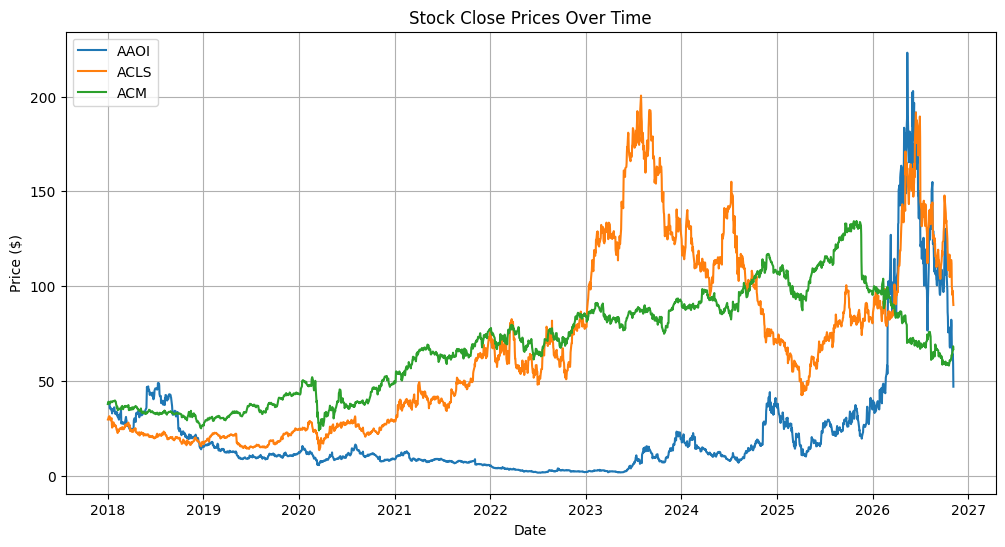

In [22]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

# Find all CSV files in the output directory
csv_files = glob.glob(output_dir + "/*.csv")
print(f"Found {len(csv_files)} CSV files:", csv_files)

# Load and plot the first available dataset as an example
if csv_files:
    df = pd.read_csv(csv_files[0])
    print("\nData Columns:", df.columns)
    display(df.head())

    # Plot close prices for a few tickers if structured as panel data
    if 'Date' in df.columns or 'date' in df.columns:
        date_col = 'Date' if 'Date' in df.columns else 'date'
        df[date_col] = pd.to_datetime(df[date_col])

        # If the dataset contains multiple tickers
        if 'Ticker' in df.columns or 'ticker' in df.columns:
            ticker_col = 'Ticker' if 'Ticker' in df.columns else 'ticker'
            unique_tickers = df[ticker_col].unique()
            print(f"Unique tickers in dataset: {unique_tickers[:10]}...")

            # Plot top 3 tickers
            plt.figure(figsize=(12, 6))
            for ticker in unique_tickers[:3]:
                ticker_df = df[df[ticker_col] == ticker].sort_values(by=date_col)
                close_col = 'Close' if 'Close' in df.columns else ('close' if 'close' in df.columns else df.columns[4])
                plt.plot(ticker_df[date_col], ticker_df[close_col], label=ticker)
            plt.title('Stock Close Prices Over Time')
            plt.xlabel('Date')
            plt.ylabel('Price ($)')
            plt.legend()
            plt.grid(True)
            plt.show()
else:
    print("No CSV files found to plot.")

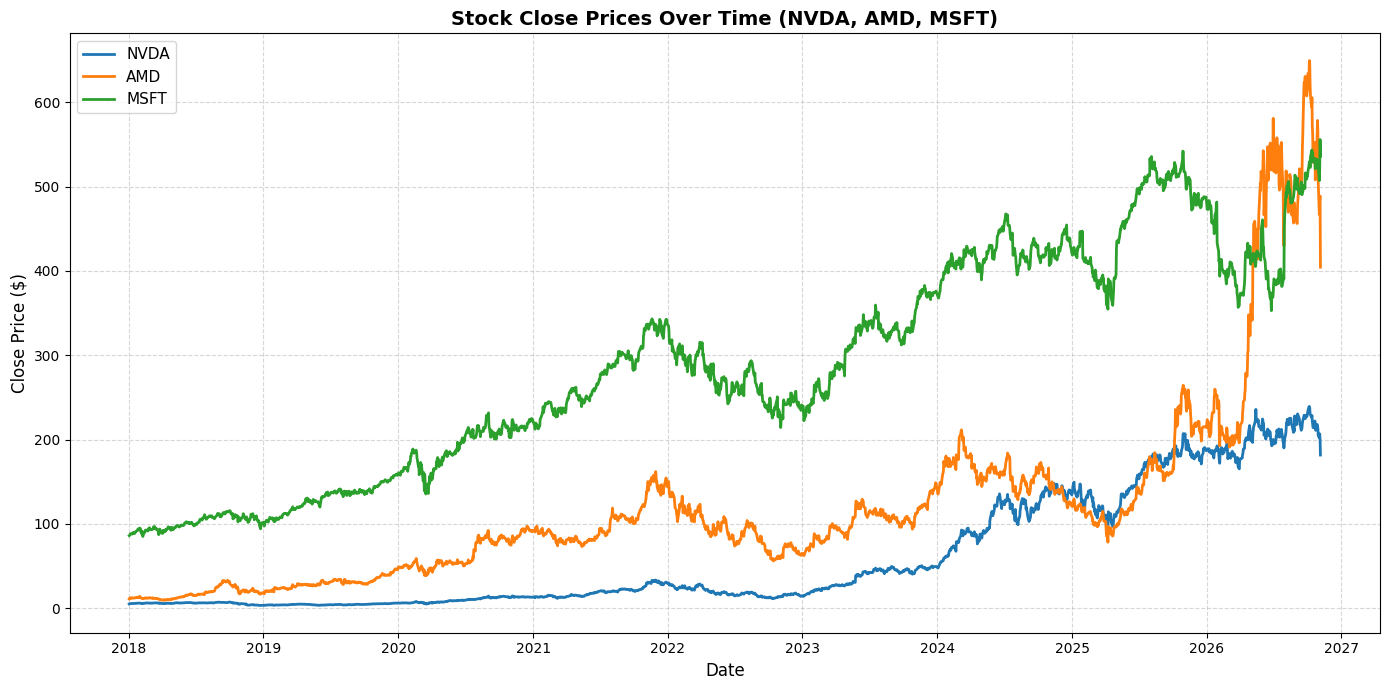

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the specific panel dataset
file_path = "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/output/stock_training_panel.csv"
df_panel = pd.read_csv(file_path)
df_panel['date'] = pd.to_datetime(df_panel['date'])

# Filter to plot a few highly recognizable tickers
target_tickers = ['NVDA', 'AMD', 'MSFT']
plt.figure(figsize=(14, 7))

for ticker in target_tickers:
    ticker_data = df_panel[df_panel['ticker'] == ticker].sort_values('date')
    if not ticker_data.empty:
        plt.plot(ticker_data['date'], ticker_data['close'], label=ticker, linewidth=2)

plt.title('Stock Close Prices Over Time (NVDA, AMD, MSFT)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close Price ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

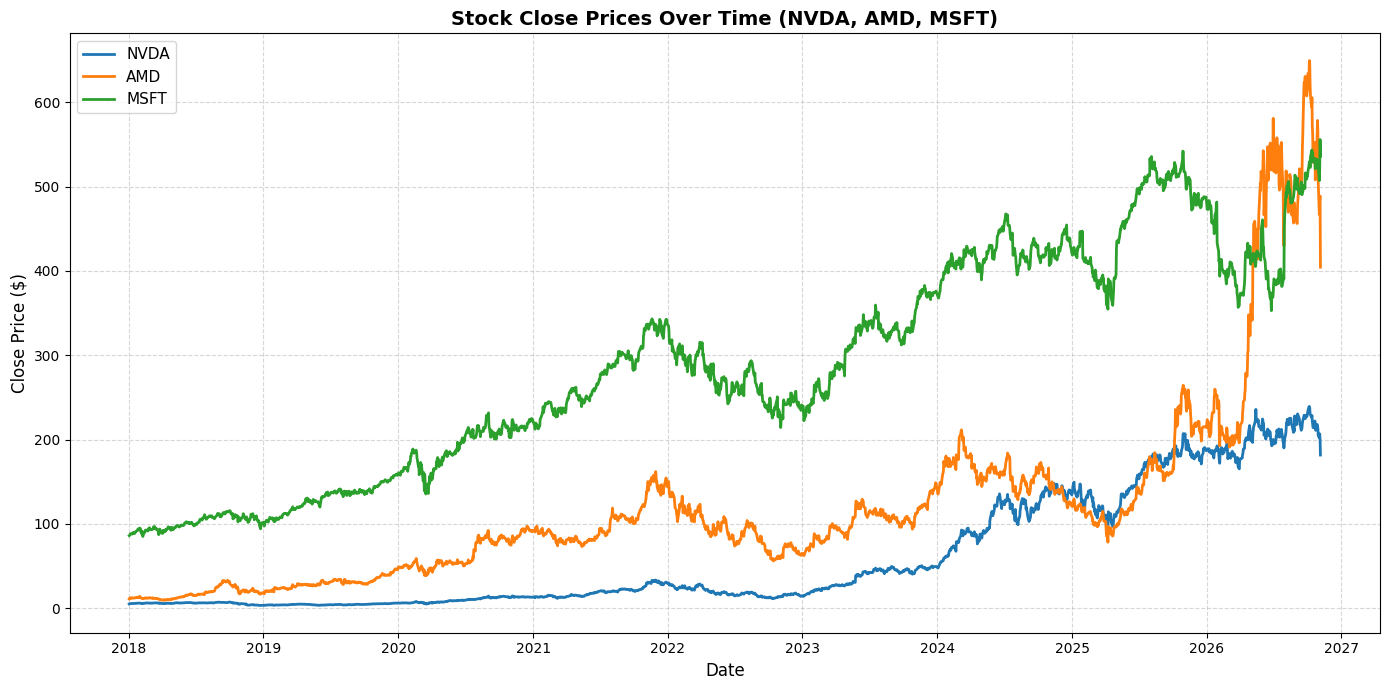

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the specific panel dataset
file_path = "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/output/stock_training_panel.csv"
df_panel = pd.read_csv(file_path)
df_panel['date'] = pd.to_datetime(df_panel['date'])

# Filter to plot a few highly recognizable tickers
target_tickers = ['NVDA', 'AMD', 'MSFT']
plt.figure(figsize=(14, 7))

for ticker in target_tickers:
    ticker_data = df_panel[df_panel['ticker'] == ticker].sort_values('date')
    if not ticker_data.empty:
        plt.plot(ticker_data['date'], ticker_data['close'], label=ticker, linewidth=2)

plt.title('Stock Close Prices Over Time (NVDA, AMD, MSFT)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close Price ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

./My-Daily-Python-Learning/Daily Stock Market Prediction/dataset/to_download/ai_infrastructure_100_tickers.csv
